In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import os
from ast import literal_eval
from collections import Counter
import math
import numpy as np
import seaborn as sns

In [2]:
username = os.path.expanduser('~')
username

'/home/ehdgus7279'

In [3]:
benchmarks = [
    # High-sharing Apps
    'gemm',
    'lu',
    'spmv',
    'mm3',
    'mm2',
    'matrixmultiplication',
    'syr2k',
    'gups',    
    'mis',
    'matrixtranspose',
    'stencil2d',
    'gaussian',

    # Low-sharing Apps
    'fdtd2d',
    'fastwalshtransform',
    'jacobi1d',
    'relu',
    'pagerank',
    'bfs',
    'color',
    'convolution2d',
    'sssp',
    'fir',
    'fft',
    'bitonicsort',
]

In [4]:
num_chiplets = 36
ns = 0.000000001

In [5]:
base_dir=f'{username}/mgvm/results/memory-traces'
date = "20260211-235812"
print(base_dir)

/home/ehdgus7279/mgvm/results/memory-traces


Processing gemm at /home/ehdgus7279/mgvm/results/memory-traces/20260211-235812/shared-pc-metrics/gemm_shared_pc_metrics.csv


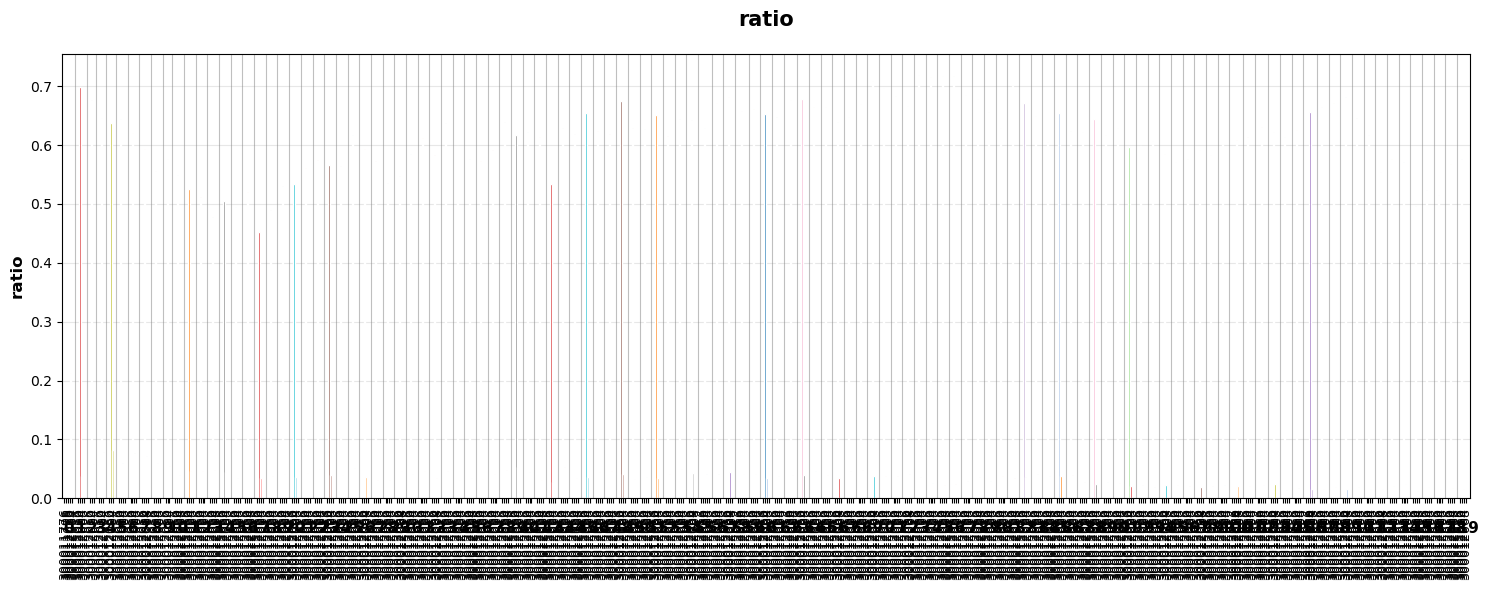

In [11]:
"""
벤치마크 별, 시간마다의 PC metric (access count, shared chiplets, access count ratio, number of cachelines)
"""

# 루프 밖에서 디렉토리 생성 (모든 벤치마크 공통)
trace_dir = f'{username}/mgvm/results/memory-traces/{date}'
result_dir = f'{trace_dir}/shared-pc-metrics'

for benchmark in benchmarks:
    if benchmark != "gemm":
        break
    result_file = f"{result_dir}/{benchmark}_shared_pc_metrics.csv"
    
    if not os.path.exists(result_file):
        print(f"  Skip: No file {result_file}")
        continue
    
    print(f"Processing {benchmark} at {result_file}")
    
    # 1. 데이터 로드 + 칩렛 확장 (한 번만!)
    df = pd.read_csv(result_file, skipinitialspace=True)

    # 데이터 정렬 (Period -> PC 순서)
    df = df.sort_values(by=['period', 'pc']).reset_index(drop=True)

    # ---------------------------------------------------------
    # 2. X축 좌표 계산 (그룹 간 간격 추가)
    # ---------------------------------------------------------
    x_pos = []
    x_labels = []
    group_centers = []
    group_labels = []

    current_x = 0
    group_gap = 2.0  # Period 간의 간격 (데이터 개수에 따라 조절)
    bar_width = 0.6

    # Period 별로 순회
    for period in df['period'].unique():
        period_data = df[df['period'] == period]
        
        start_x = current_x
        
        # 해당 Period 내의 PC들에 대한 좌표 생성
        for _, row in period_data.iterrows():
            x_pos.append(current_x)
            x_labels.append(str(int(row['pc']))) # 정수로 변환 후 문자열
            current_x += 1.0 # 다음 막대 위치
        
        end_x = current_x - 1.0
        
        # 그룹(Period) 라벨의 중심 위치 저장
        group_centers.append((start_x + end_x) / 2)
        group_labels.append(f"{period}") # 혹은 f"Period {period}"
        
        # 다음 그룹을 위해 간격 띄우기
        current_x += group_gap

    # ---------------------------------------------------------
    # 3. 그래프 그리기
    # ---------------------------------------------------------
    fig, ax = plt.subplots(figsize=(15, 6)) # 가로로 긴 비율

    # 막대 그래프 (색상은 다채롭게)
    colors = plt.cm.tab20.colors # tab20 컬러맵 사용 (다양한 색상)
    # 데이터 개수만큼 색상 리스트 반복 생성
    bar_colors = [colors[i % len(colors)] for i in range(len(df))]

    bars = ax.bar(x_pos, df['ratio'], width=bar_width, color=bar_colors, edgecolor='white')

    # ---------------------------------------------------------
    # 4. 축 및 라벨 설정 (이미지 스타일 모방)
    # ---------------------------------------------------------
    # X축 (PC 값) - 90도 회전
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, rotation=90, fontsize=9)

    # Y축
    ax.set_ylabel('ratio', fontsize=12, fontweight='bold')
    ax.set_title('ratio', fontsize=15, fontweight='bold', pad=20)

    # Y축 그리드 (가로선만)
    ax.yaxis.grid(True, linestyle='-', alpha=0.3)
    ax.set_axisbelow(True) # 그리드가 막대 뒤로 가게 설정

    # X축 범위 조정 (양옆 여백)
    ax.set_xlim(-1, current_x - group_gap + 1)

    # ---------------------------------------------------------
    # 5. 그룹(Period) 구분선 및 라벨 추가
    # ---------------------------------------------------------
    # X축 아래에 Period 라벨 추가 (Secondary X-axis 효과)
    for center, label in zip(group_centers, group_labels):
        ax.text(center, -0.05, label, transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontweight='bold', fontsize=11)

    # 그룹 사이 구분선 (Vertical Line)
    # 그룹 간격의 중간 지점에 선 그리기
    idx = 0
    period_counts = df['period'].value_counts(sort=False).sort_index()
    accumulated_count = 0

    # 구분선 위치 계산을 위해 다시 순회하지 않고, 
    # 위에서 계산한 x_pos 구조를 활용해 경계선 추가
    # 간단하게: 그룹과 그룹 사이의 빈 공간(gap) 중앙에 선 긋기
    prev_group_end_x = -1

    # 데이터프레임 다시 순회하며 경계 찾기
    periods = df['period'].unique()
    current_idx = 0
    for i, p in enumerate(periods):
        count = len(df[df['period'] == p])
        
        # 그룹의 끝 인덱스
        group_end_idx = current_idx + count - 1
        group_end_x_pos = x_pos[group_end_idx]
        
        # 마지막 그룹이 아니면 구분선 그리기
        if i < len(periods) - 1:
            # 현재 그룹 끝과 다음 그룹 시작의 중간
            next_group_start_x_pos = x_pos[group_end_idx + 1]
            line_x = (group_end_x_pos + next_group_start_x_pos) / 2
            
            # 회색 점선으로 구분선
            ax.axvline(x=line_x, color='gray', linestyle='-', linewidth=0.8, alpha=0.5)
            # 구분선 아래쪽은 조금 짧게 보이게 하려면 ylim 조절이 필요하나, axvline은 전체를 그음
            
        current_idx += count

    plt.tight_layout()
    plt.show()

